# 03. La memoria de una serie

Teórica de series temporales, Analítica de Datos (UdeSA). Este cuaderno acompaña el bloque 3 de la clase.

Cuánto se parece cada valor a los anteriores, y qué consecuencias tiene eso: autocorrelación, caminatas aleatorias, correlaciones que aparecen sin relación real, estacionariedad.

Contenido:

1. Rezagos y autocorrelación (ACF y PACF).
2. Ruido blanco y caminata aleatoria.
3. ¿Cuál es la serie real?
4. Correlación espuria.
5. Estacionariedad y diferencias.
6. La prueba de Dickey-Fuller aumentada (ADF).
7. Un proceso autorregresivo de orden 1.

In [1]:
import sys

# Dirección de los datos cuando el notebook corre en Colab.
# Si los datos se suben a otro lado, hay que cambiar esta constante.
URL_DATOS_COLAB = "https://raw.githubusercontent.com/ferkrodriguez98/teorica-series-temporales/main/datos_clase/"

EN_COLAB = "google.colab" in sys.modules
BASE = URL_DATOS_COLAB if EN_COLAB else "../datos_clase/"
print("Datos:", BASE)

Datos: ../datos_clase/


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Colores: tinta para lo observado, rojo para pronósticos y resaltados
TINTA, GRIS, ROJO = "#1f2430", "#9aa0a6", "#c62828"
LINEAS = {"A": "#1a9fd0", "B": "#d7182a", "C": "#1d4f9c", "D": "#008a57", "E": "#6c2c87", "H": "#e0a800"}
ECOBICI = "#d4a017"

warnings.simplefilter("ignore", FutureWarning)   # avisos de cambios en versiones futuras de las librerías

plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 100, "savefig.bbox": "tight",
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b0b0b0",
    "axes.titlesize": 11.5, "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": "#444444", "xtick.color": "#555555", "ytick.color": "#555555",
    "legend.frameon": False, "legend.fontsize": 9.5, "lines.linewidth": 1.1,
})

def num(x, dec=0):
    # Número con punto de miles y coma decimal
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def pct(x, dec=0):
    return num(100 * x, dec) + " %"

en_millones = FuncFormatter(lambda v, _: num(v / 1e6, 1))
en_miles = FuncFormatter(lambda v, _: num(v / 1e3))

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]

def acf_simple(s, kmax):
    # Correlación de Pearson entre la serie y su rezago k, para k = 1..kmax (ignora los pares con faltantes)
    s = pd.Series(s)
    return pd.Series([s.autocorr(k) for k in range(1, kmax + 1)], index=range(1, kmax + 1))

def barras_acf(ax, valores, titulo, referencia=None):
    ax.vlines(valores.index, 0, valores.values, color=TINTA, lw=1.4)
    ax.axhline(0, color=GRIS, lw=0.8)
    if referencia is not None:
        ax.plot(referencia.index, referencia.values, color=ROJO, ls="--", lw=1.2, label="teórica")
        ax.legend(loc="upper right")
    ax.set_title(titulo)
    ax.set_xlabel("rezago")

## 1. Rezagos y autocorrelación

Total diario del subte de 2023 a 2025. `shift(k)` corre la serie k días: en cada fecha queda el valor de k días antes. La correlación entre la serie y su rezago es la autocorrelación de orden k.

In [3]:
total = pd.read_csv(BASE + "subte_diario_total.csv", parse_dates=["fecha"], index_col="fecha")["pax"]
s = total.loc["2023":"2025"]
print("Días:", len(s), "| sin datos:", s.isna().sum())

tabla = pd.DataFrame({"hoy": s, "hace 1 día": s.shift(1), "hace 7 días": s.shift(7)})
tabla.loc["2025-06-02":"2025-06-10"]

Días: 1096 | sin datos: 3


,hoy,hace 1 día,hace 7 días
fecha,,,
2025-06-02,777390.0,195959.0,736647.0
2025-06-03,812827.0,777390.0,728619.0
2025-06-04,855492.0,812827.0,815753.0
2025-06-05,843008.0,855492.0,804031.0
2025-06-06,805015.0,843008.0,772809.0
2025-06-07,386927.0,805015.0,366438.0
2025-06-08,207776.0,386927.0,195959.0
2025-06-09,805162.0,207776.0,777390.0
2025-06-10,858160.0,805162.0,812827.0


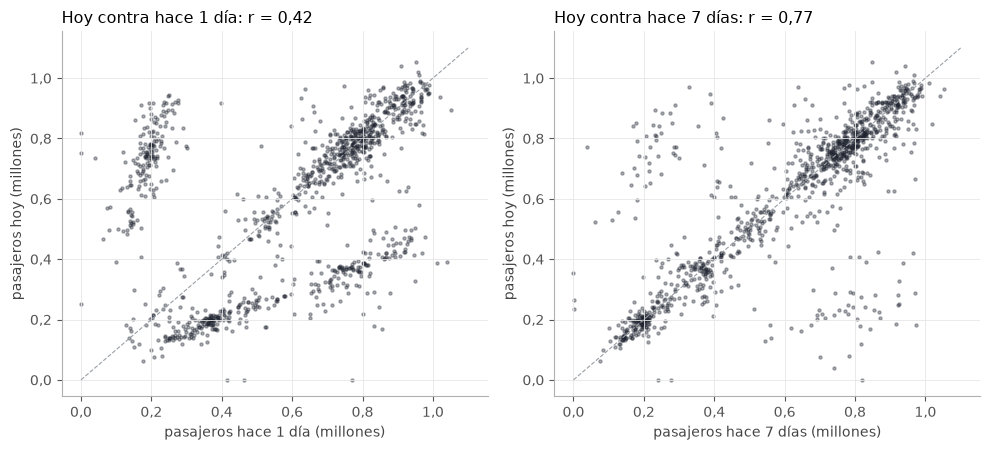

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, k in zip(axes, (1, 7)):
    ax.scatter(s.shift(k), s, s=5, color=TINTA, alpha=0.35)
    ax.plot([0, 1.1e6], [0, 1.1e6], color=GRIS, ls="--", lw=0.8)
    ax.set_title(f"Hoy contra hace {k} {'día' if k == 1 else 'días'}: r = {num(s.autocorr(k), 2)}")
    ax.set_xlabel(f"pasajeros hace {k} {'día' if k == 1 else 'días'} (millones)")
    ax.set_ylabel("pasajeros hoy (millones)")
    ax.xaxis.set_major_formatter(en_millones)
    ax.yaxis.set_major_formatter(en_millones)
fig.tight_layout()

Con un día de rezago, los pares de dos días hábiles quedan sobre la diagonal, pero los de viernes a sábado, sábado a domingo y domingo a lunes quedan lejos. Con siete días cada día queda contra el mismo día de la semana anterior y la nube se pega a la diagonal.

La **función de autocorrelación** (ACF) es esa correlación para cada rezago.

Rezagos 7, 14, 21 y 28: 0,77, 0,76, 0,74, 0,73


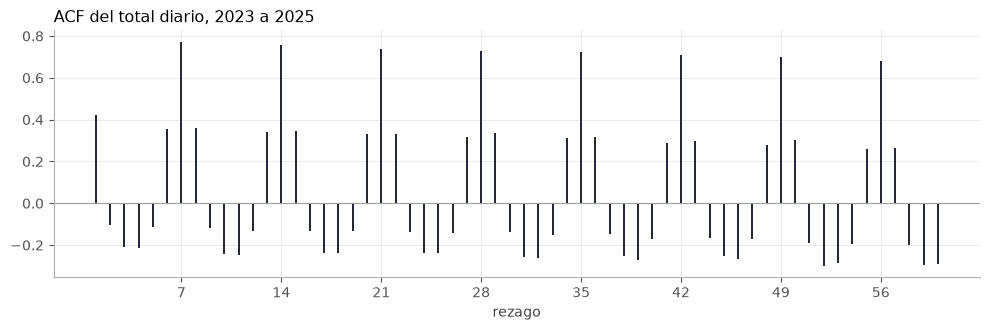

In [5]:
acf_subte = acf_simple(s, 60)
fig, ax = plt.subplots(figsize=(10, 3.4))
barras_acf(ax, acf_subte, "ACF del total diario, 2023 a 2025")
ax.set_xticks(range(7, 61, 7))
fig.tight_layout()
print("Rezagos 7, 14, 21 y 28:", ", ".join(num(acf_subte[k], 2) for k in (7, 14, 21, 28)))

Los picos en 7, 14, 21... son el ciclo semanal. `statsmodels` tiene `plot_acf` y `plot_pacf`, que no aceptan faltantes (se interpolan los días sin datos). La banda gris es el intervalo del 95 % bajo la hipótesis de que la serie es ruido blanco: las barras que salen de la banda son autocorrelaciones que difícilmente aparecerían por azar.

La **autocorrelación parcial** (PACF) de orden k es la correlación con el rezago k una vez descontado lo que explican los rezagos 1 a k−1.

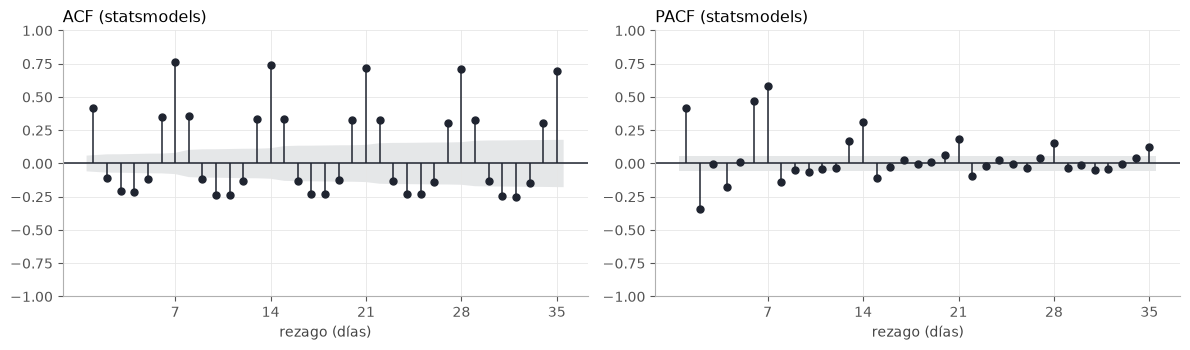

In [6]:
si = s.interpolate("time")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot_acf(si, lags=35, ax=axes[0], zero=False, color=TINTA, vlines_kwargs={"colors": TINTA}, title="ACF (statsmodels)")
plot_pacf(si, lags=35, ax=axes[1], zero=False, method="ywm", color=TINTA, vlines_kwargs={"colors": TINTA}, title="PACF (statsmodels)")
from matplotlib.collections import PolyCollection
for ax in axes:
    ax.set_xticks(range(7, 36, 7))
    ax.set_xlabel("rezago (días)")
    for c in ax.collections:
        if isinstance(c, PolyCollection):
            c.set_facecolor(GRIS)   # banda del 95 % en gris
fig.tight_layout()

## 2. Ruido blanco y caminata aleatoria

- **Ruido blanco**: cada valor es un sorteo independiente, $x_t = \varepsilon_t$. No tiene memoria.
- **Caminata aleatoria**: cada valor es el anterior más un sorteo, $x_t = x_{t-1} + \varepsilon_t$. Es la suma acumulada del ruido blanco: recuerda todo.

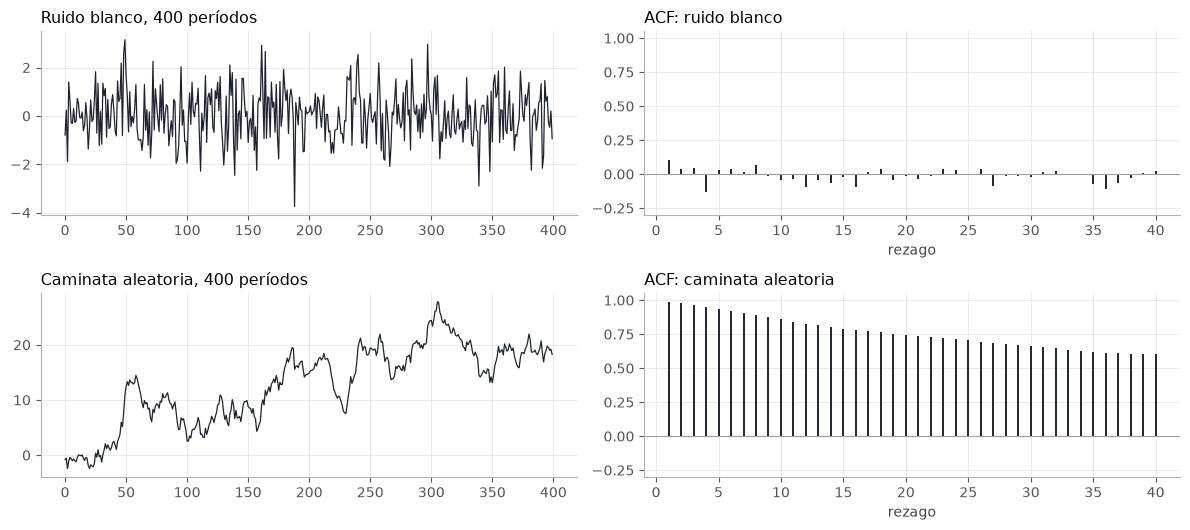

In [7]:
rng = np.random.default_rng(2026)
ruido = pd.Series(rng.normal(size=400))
caminata = ruido.cumsum()

fig, axes = plt.subplots(2, 2, figsize=(12, 5.4))
for fila, (serie, nombre) in enumerate(((ruido, "Ruido blanco"), (caminata, "Caminata aleatoria"))):
    axes[fila, 0].plot(serie.index, serie.values, color=TINTA, lw=0.9)
    axes[fila, 0].set_title(f"{nombre}, 400 períodos")
    barras_acf(axes[fila, 1], acf_simple(serie, 40), f"ACF: {nombre.lower()}")
    axes[fila, 1].set_ylim(-0.3, 1.05)
fig.tight_layout()

La ACF del ruido blanco queda cerca de cero en todos los rezagos. La de la caminata empieza cerca de 1 y baja muy despacio: cada valor se parece mucho a los anteriores porque los contiene.

## 3. ¿Cuál es la serie real?

Uno de estos cuatro paneles es el logaritmo del dólar blue (venta, de lunes a viernes) en 500 días seguidos desde junio de 2020. Los otros tres son caminatas aleatorias simuladas cuyos pasos tienen la media y el desvío de las variaciones diarias del dólar en esa misma ventana.

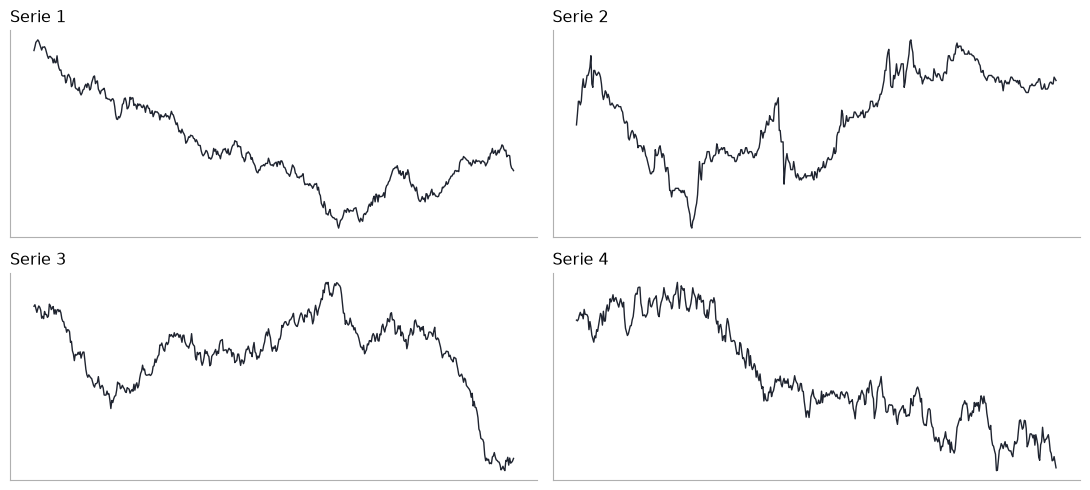

In [8]:
dolar = pd.read_csv(BASE + "dolar_blue.csv", parse_dates=["fecha"], index_col="fecha")["venta"]
dolar = dolar.loc["2020-06-01":]
dolar = dolar[dolar.index.day_of_week < 5]
log_dolar = np.log(dolar)

rng = np.random.default_rng(20)
N = 500
inicio = rng.integers(0, len(log_dolar) - N)
real = log_dolar.iloc[inicio:inicio + N].to_numpy()
pasos = np.diff(real)
series = [real[0] + np.concatenate([[0], np.cumsum(rng.normal(pasos.mean(), pasos.std(), N - 1))]) for _ in range(3)]
posicion = int(rng.integers(0, 4))
series.insert(posicion, real)

fig, axes = plt.subplots(2, 2, figsize=(11, 5))
for i, (ax, x) in enumerate(zip(axes.flat, series)):
    ax.plot(x, color=TINTA, lw=1)
    ax.set_title(f"Serie {i + 1}")
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

In [9]:
cambios = (np.diff(real) == 0).mean()
print(f"La real es la serie {posicion + 1}: del {log_dolar.index[inicio].date()} al {log_dolar.index[inicio + N - 1].date()},")
print(f"el dólar blue pasó de ${num(dolar.iloc[inicio], 2)} a ${num(dolar.iloc[inicio + N - 1], 2)}.")
print(f"En el {pct(cambios)} de los días la cotización no cambió respecto del día anterior; en las simuladas cambia todos los días.")

La real es la serie 2: del 2024-06-21 al 2026-05-21,
el dólar blue pasó de $1.300,00 a $1.425,00.
En el 25 % de los días la cotización no cambió respecto del día anterior; en las simuladas cambia todos los días.


Una serie de precios se parece mucho a una caminata aleatoria. La pista para distinguirla es un detalle de cómo se registra (días sin cambio), no su forma general.

## 4. Correlación espuria

Dos caminatas aleatorias generadas por separado no tienen ninguna relación. Sin embargo, como cada una se aleja de su punto de partida, es común que dos caminatas tengan una correlación alta, positiva o negativa. Con las diferencias (el paso de cada período) eso desaparece.

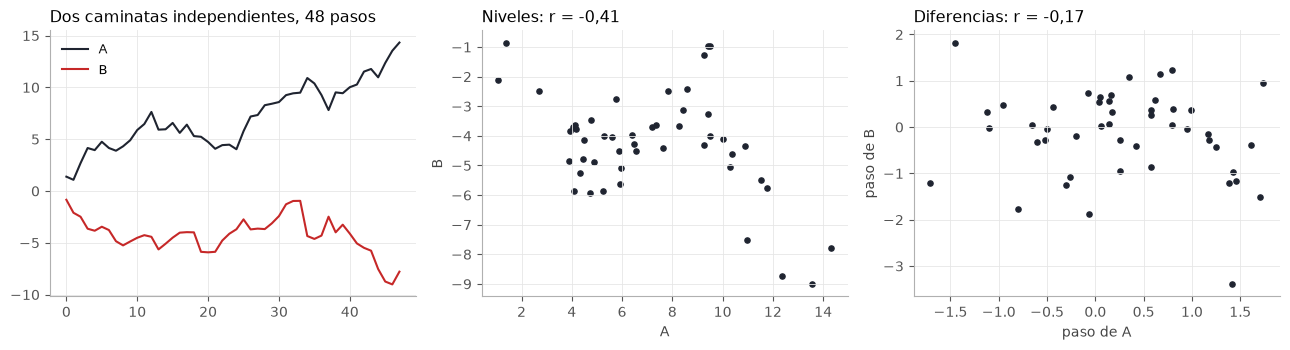

In [10]:
rng = np.random.default_rng(20261120)
a = np.cumsum(rng.normal(size=48))
b = np.cumsum(rng.normal(size=48))
r_niv = np.corrcoef(a, b)[0, 1]
r_dif = np.corrcoef(np.diff(a), np.diff(b))[0, 1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(a, color=TINTA, lw=1.5, label="A")
axes[0].plot(b, color=ROJO, lw=1.5, label="B")
axes[0].legend(); axes[0].set_title("Dos caminatas independientes, 48 pasos")
axes[1].scatter(a, b, color=TINTA, s=14); axes[1].set_title(f"Niveles: r = {num(r_niv, 2)}")
axes[1].set_xlabel("A"); axes[1].set_ylabel("B")
axes[2].scatter(np.diff(a), np.diff(b), color=TINTA, s=14); axes[2].set_title(f"Diferencias: r = {num(r_dif, 2)}")
axes[2].set_xlabel("paso de A"); axes[2].set_ylabel("paso de B")
fig.tight_layout()

Un par puede salir con correlación alta o baja por azar. Repitiendo con 500 pares se ve la distribución completa:

Niveles: la mitad de los pares tiene |r| mayor que 0,45
Diferencias: el 95 % de los pares tiene |r| menor que 0,27


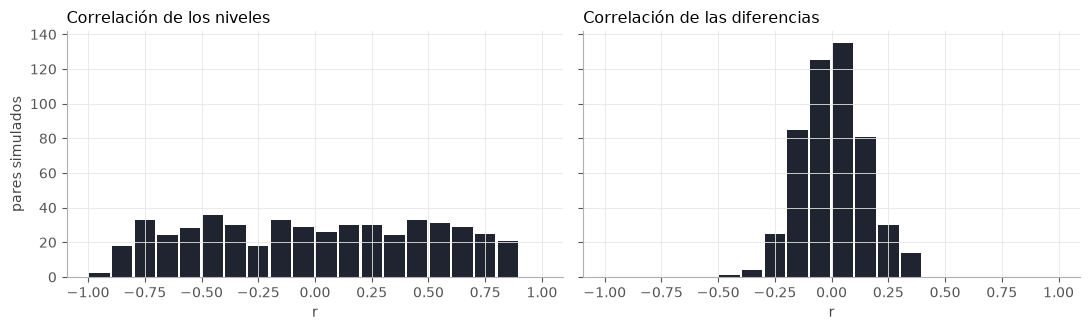

In [11]:
r_niveles, r_diferencias = [], []
for _ in range(500):
    a, b = np.cumsum(rng.normal(size=(2, 48)), axis=1)
    r_niveles.append(np.corrcoef(a, b)[0, 1])
    r_diferencias.append(np.corrcoef(np.diff(a), np.diff(b))[0, 1])
r_niveles, r_diferencias = np.array(r_niveles), np.array(r_diferencias)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
bins = np.arange(-1, 1.01, 0.1)
axes[0].hist(r_niveles, bins=bins, color=TINTA, rwidth=0.9); axes[0].set_title("Correlación de los niveles")
axes[1].hist(r_diferencias, bins=bins, color=TINTA, rwidth=0.9); axes[1].set_title("Correlación de las diferencias")
axes[0].set_ylabel("pares simulados")
for ax in axes:
    ax.set_xlabel("r")
fig.tight_layout()
print("Niveles: la mitad de los pares tiene |r| mayor que", num(np.median(np.abs(r_niveles)), 2))
print("Diferencias: el 95 % de los pares tiene |r| menor que", num(np.quantile(np.abs(r_diferencias), 0.95), 2))

### Pasajeros del subte y dólar blue, 2022 a 2025

Promedios mensuales de las dos series. El dólar sube durante casi todo el período; los pasajeros suben en 2022, bajan en 2024 y repiten su ciclo anual.

Correlación de los niveles: -0,28 | de las variaciones mensuales: -0,31
Proporción de pares simulados con |r| igual o mayor:
  en niveles: 68 % | en diferencias: 4 %


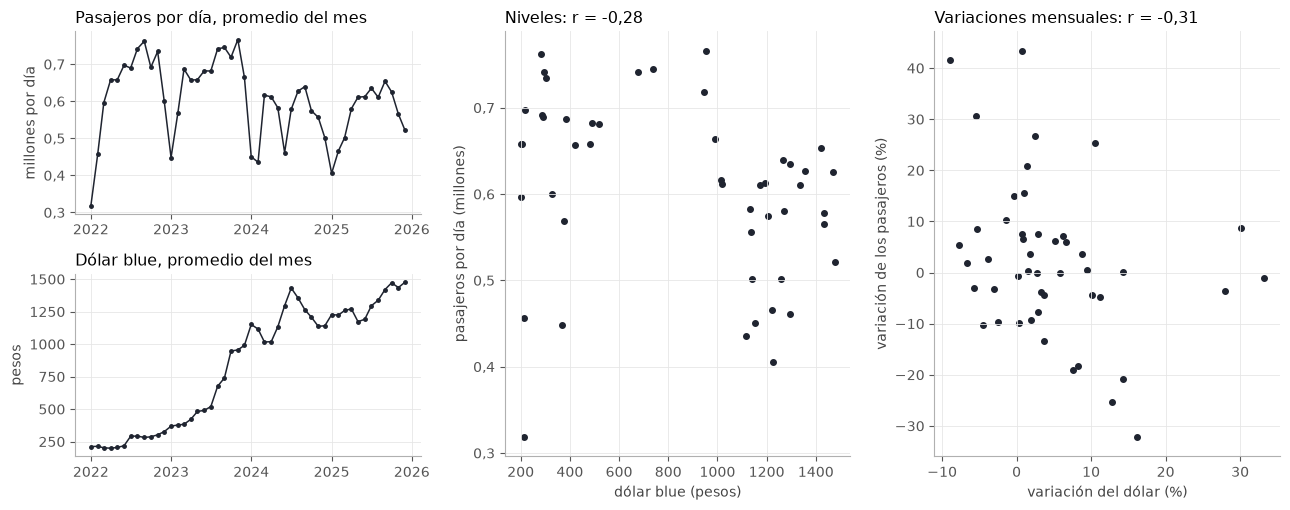

In [12]:
dolar_todo = pd.read_csv(BASE + "dolar_blue.csv", parse_dates=["fecha"], index_col="fecha")["venta"]
mensual = pd.DataFrame({
    "pasajeros": total.loc["2022":"2025"].resample("MS").mean(),
    "dolar": dolar_todo.loc["2022":"2025"].resample("MS").mean(),
})
variacion = mensual.pct_change().dropna()
r_niv = mensual["pasajeros"].corr(mensual["dolar"])
r_var = variacion["pasajeros"].corr(variacion["dolar"])

fig = plt.figure(figsize=(13, 5.2))
g = fig.add_gridspec(2, 3)
ax1, ax2 = fig.add_subplot(g[0, 0]), fig.add_subplot(g[1, 0])
ax1.plot(mensual.index, mensual["pasajeros"], color=TINTA, marker="o", ms=2.5)
ax1.yaxis.set_major_formatter(en_millones); ax1.set_ylabel("millones por día"); ax1.set_title("Pasajeros por día, promedio del mes")
ax2.plot(mensual.index, mensual["dolar"], color=TINTA, marker="o", ms=2.5)
ax2.set_ylabel("pesos"); ax2.set_title("Dólar blue, promedio del mes")
for ax in (ax1, ax2):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax3, ax4 = fig.add_subplot(g[:, 1]), fig.add_subplot(g[:, 2])
ax3.scatter(mensual["dolar"], mensual["pasajeros"], color=TINTA, s=16)
ax3.yaxis.set_major_formatter(en_millones)
ax3.set_xlabel("dólar blue (pesos)"); ax3.set_ylabel("pasajeros por día (millones)"); ax3.set_title(f"Niveles: r = {num(r_niv, 2)}")
ax4.scatter(100 * variacion["dolar"], 100 * variacion["pasajeros"], color=TINTA, s=16)
ax4.set_xlabel("variación del dólar (%)"); ax4.set_ylabel("variación de los pasajeros (%)"); ax4.set_title(f"Variaciones mensuales: r = {num(r_var, 2)}")
fig.tight_layout()

print("Correlación de los niveles:", num(r_niv, 2), "| de las variaciones mensuales:", num(r_var, 2))
print("Proporción de pares simulados con |r| igual o mayor:")
print("  en niveles:", pct((np.abs(r_niveles) >= abs(r_niv)).mean()), "| en diferencias:", pct((np.abs(r_diferencias) >= abs(r_var)).mean()))

Cada correlación se lee contra lo que producen series sin ninguna relación. La de los niveles se compara con los 500 pares de caminatas: si muchos pares independientes llegan a una correlación igual o mayor, el número no dice nada sobre una relación entre las series. La de las variaciones se compara con las correlaciones de las diferencias. Si pocos pares la alcanzan, es difícil atribuirla al azar, aunque eso todavía no explica por qué se mueven juntas: las variaciones mensuales de los pasajeros tienen su propio ciclo anual (enero, marzo, julio) y cualquier serie con saltos en esos meses va a mostrar alguna correlación con ellas.

## 5. Estacionariedad

Una serie es **estacionaria** si su media, su variabilidad y su autocorrelación no dependen del momento en que se la mire. Los modelos clásicos (AR, ARMA) estiman esas cantidades con el pasado y las usan para pronosticar; si cambian con el tiempo, lo estimado deja de describir lo que viene.

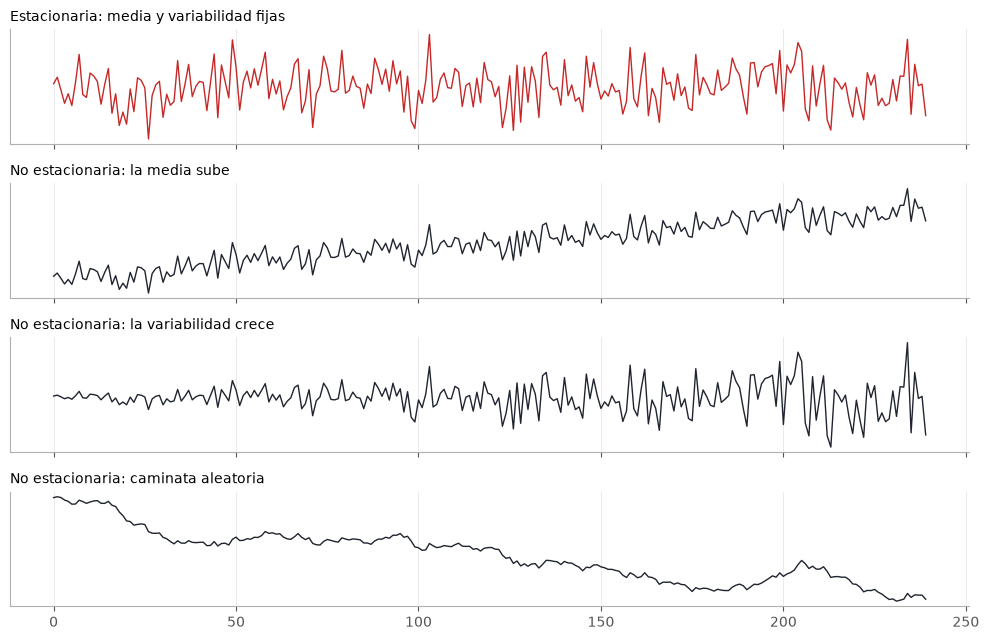

In [13]:
rng = np.random.default_rng(7)
e = rng.normal(size=240)
t = np.arange(240)
casos = {
    "Estacionaria: media y variabilidad fijas": e,
    "No estacionaria: la media sube": e + 0.03 * t,
    "No estacionaria: la variabilidad crece": e * (0.25 + 2.2 * t / 240),
    "No estacionaria: caminata aleatoria": np.cumsum(e),
}
fig, axes = plt.subplots(4, 1, figsize=(10, 6.5), sharex=True)
for ax, (titulo, x) in zip(axes, casos.items()):
    ax.plot(x, color=ROJO if titulo.startswith("Estacionaria") else TINTA, lw=1)
    ax.set_title(titulo, fontsize=10)
    ax.set_yticks([])
fig.tight_layout()

**Diferenciar** es restar a cada valor el de un período anterior: `diff(1)` resta el día anterior y `diff(7)` el mismo día de la semana anterior. Saca tendencias y ciclos fijos. Las diferencias de una caminata aleatoria son ruido blanco.

Total diario, 2022 a 2025: ACF en 1 = 0,43, en 7 = 0,78, en 56 = 0,68; máximo |ACF| desde el 8: 0,76
Diferencia de 1 día: ACF en 1 = -0,05, en 7 = 0,72, en 56 = 0,72; máximo |ACF| desde el 8: 0,72
Diferencia de 7 días: ACF en 1 = 0,25, en 7 = -0,45, en 56 = 0,00; máximo |ACF| desde el 8: 0,11


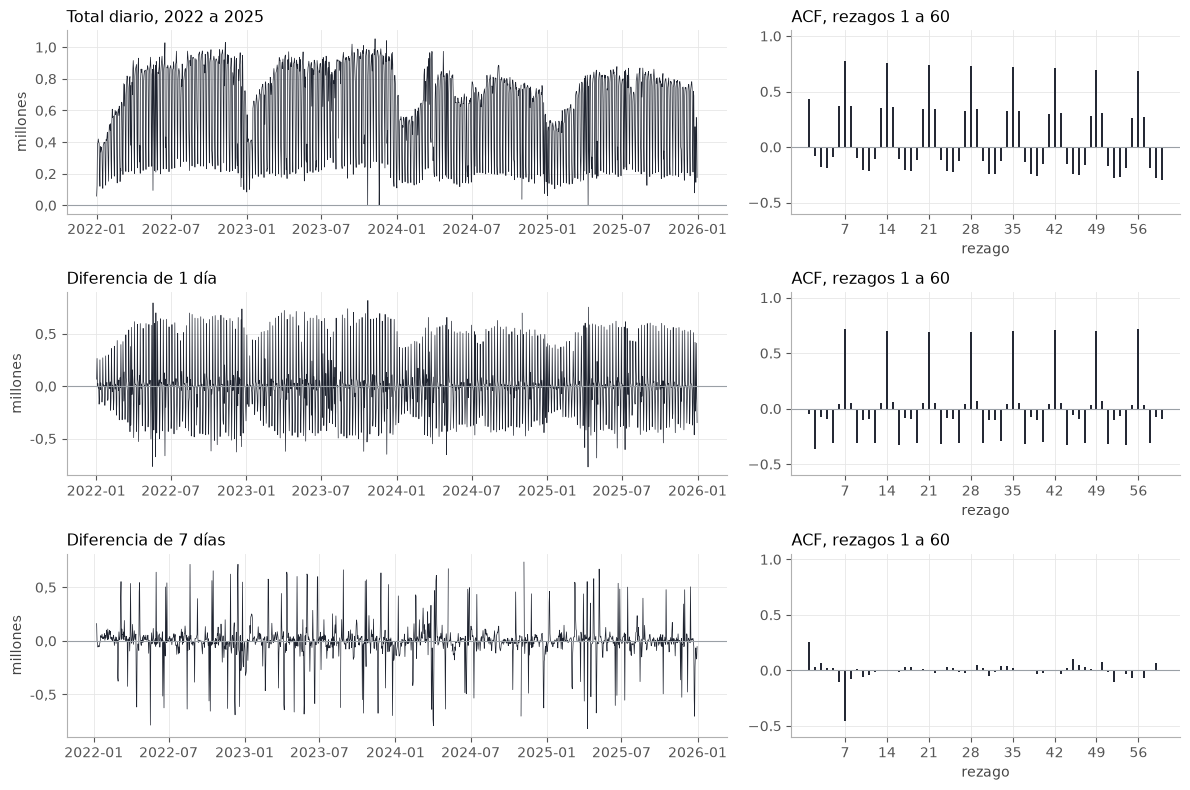

In [14]:
s = total.loc["2022":"2025"]
versiones = {
    "Total diario, 2022 a 2025": s,
    "Diferencia de 1 día": s.diff(1),
    "Diferencia de 7 días": s.diff(7),
}
fig, axes = plt.subplots(3, 2, figsize=(12, 8), gridspec_kw={"width_ratios": [1.7, 1]})
for fila, (titulo, x) in enumerate(versiones.items()):
    axes[fila, 0].plot(x.index, x.values, color=TINTA, lw=0.5)
    axes[fila, 0].axhline(0, color=GRIS, lw=0.8)
    axes[fila, 0].set_title(titulo)
    axes[fila, 0].yaxis.set_major_formatter(en_millones)
    axes[fila, 0].set_ylabel("millones")
    a = acf_simple(x, 60)
    barras_acf(axes[fila, 1], a, "ACF, rezagos 1 a 60")
    axes[fila, 1].set_xticks(range(7, 61, 7))
    axes[fila, 1].set_ylim(-0.6, 1.05)
    print(f"{titulo}: ACF en 1 = {num(a[1], 2)}, en 7 = {num(a[7], 2)}, en 56 = {num(a[56], 2)}; máximo |ACF| desde el 8: {num(a.loc[8:].abs().max(), 2)}")
fig.tight_layout()

La diferencia de 1 día saca el nivel pero no el ciclo semanal: la ACF sigue alta en 7, 14, 21... La diferencia de 7 días saca el ciclo semanal. El valor negativo en el rezago 7 aparece porque un día atípico entra dos veces en la serie diferenciada: sumando el día en que ocurre y restando siete días después.

## 6. Prueba de Dickey-Fuller aumentada

`adfuller` contrasta la hipótesis nula de que la serie tiene una **raíz unitaria**, es decir, que se comporta como una caminata aleatoria (más, eventualmente, una deriva). Un p-valor chico (menor que 0,05, por ejemplo) es evidencia contra la raíz unitaria: la serie vuelve a su media. Un p-valor grande no prueba que haya raíz unitaria; dice que los datos no alcanzan para descartarla.

La prueba agrega rezagos de las diferencias para absorber la autocorrelación; `autolag="AIC"` elige cuántos.

In [15]:
def adf(x):
    est, p, rezagos, n, *_ = adfuller(pd.Series(x).dropna(), autolag="AIC")
    return {"estadístico": round(est, 2), "p-valor": round(p, 4), "rezagos": rezagos, "observaciones": n,
            "al 5 %": "se rechaza la raíz unitaria" if p < 0.05 else "no se rechaza"}

si = s.interpolate("time")
resultados = pd.DataFrame({
    "ruido blanco simulado": adf(ruido),
    "caminata simulada": adf(caminata),
    "log del dólar blue": adf(log_dolar),
    "diferencia del log del dólar": adf(log_dolar.diff()),
    "subte, nivel": adf(si),
    "subte, diferencia de 1 día": adf(si.diff(1)),
    "subte, diferencia de 7 días": adf(si.diff(7)),
}).T
resultados

,estadístico,p-valor,rezagos,observaciones,al 5 %
ruido blanco simulado,-10.64,0.0,3,396,se rechaza la raíz unitaria
caminata simulada,-2.14,0.2302,5,394,no se rechaza
log del dólar blue,-1.1,0.7165,6,1680,no se rechaza
diferencia del log del dólar,-16.3,0.0,5,1680,se rechaza la raíz unitaria
"subte, nivel",-3.63,0.0052,21,1439,se rechaza la raíz unitaria
"subte, diferencia de 1 día",-13.0,0.0,20,1439,se rechaza la raíz unitaria
"subte, diferencia de 7 días",-9.18,0.0,23,1430,se rechaza la raíz unitaria


Las simuladas dan lo esperado: se rechaza en el ruido blanco y no en la caminata. Con el dólar pasa lo mismo que con la caminata: no se rechaza en niveles y sí en diferencias.

La serie del subte en niveles merece cuidado. La prueba puede rechazar la raíz unitaria porque la serie vuelve al nivel de la semana todo el tiempo (el ciclo semanal es fuerte), aunque su nivel de fondo cambie entre años y su ciclo semanal sea fijo. ADF mira una sola forma de no estacionariedad, la de la caminata aleatoria; tendencias que cambian de pendiente, quiebres y ciclos estacionales hay que mirarlos con gráficos y con la ACF.

## 7. Un proceso autorregresivo de orden 1

$$x_t = \phi\, x_{t-1} + \varepsilon_t$$

Con $\phi = 0$ es ruido blanco; con $\phi = 1$, una caminata aleatoria. En el medio, cada shock se va olvidando: después de k períodos queda $\phi^k$ de su efecto, que es también la autocorrelación teórica de orden k. Los 400 shocks son los mismos en todas las series, así que lo único que cambia es $\phi$.

φ = 0,50: un shock pierde la mitad de su efecto en 1,0 períodos
φ = 0,90: un shock pierde la mitad de su efecto en 6,6 períodos
φ = 0,99: un shock pierde la mitad de su efecto en 69,0 períodos


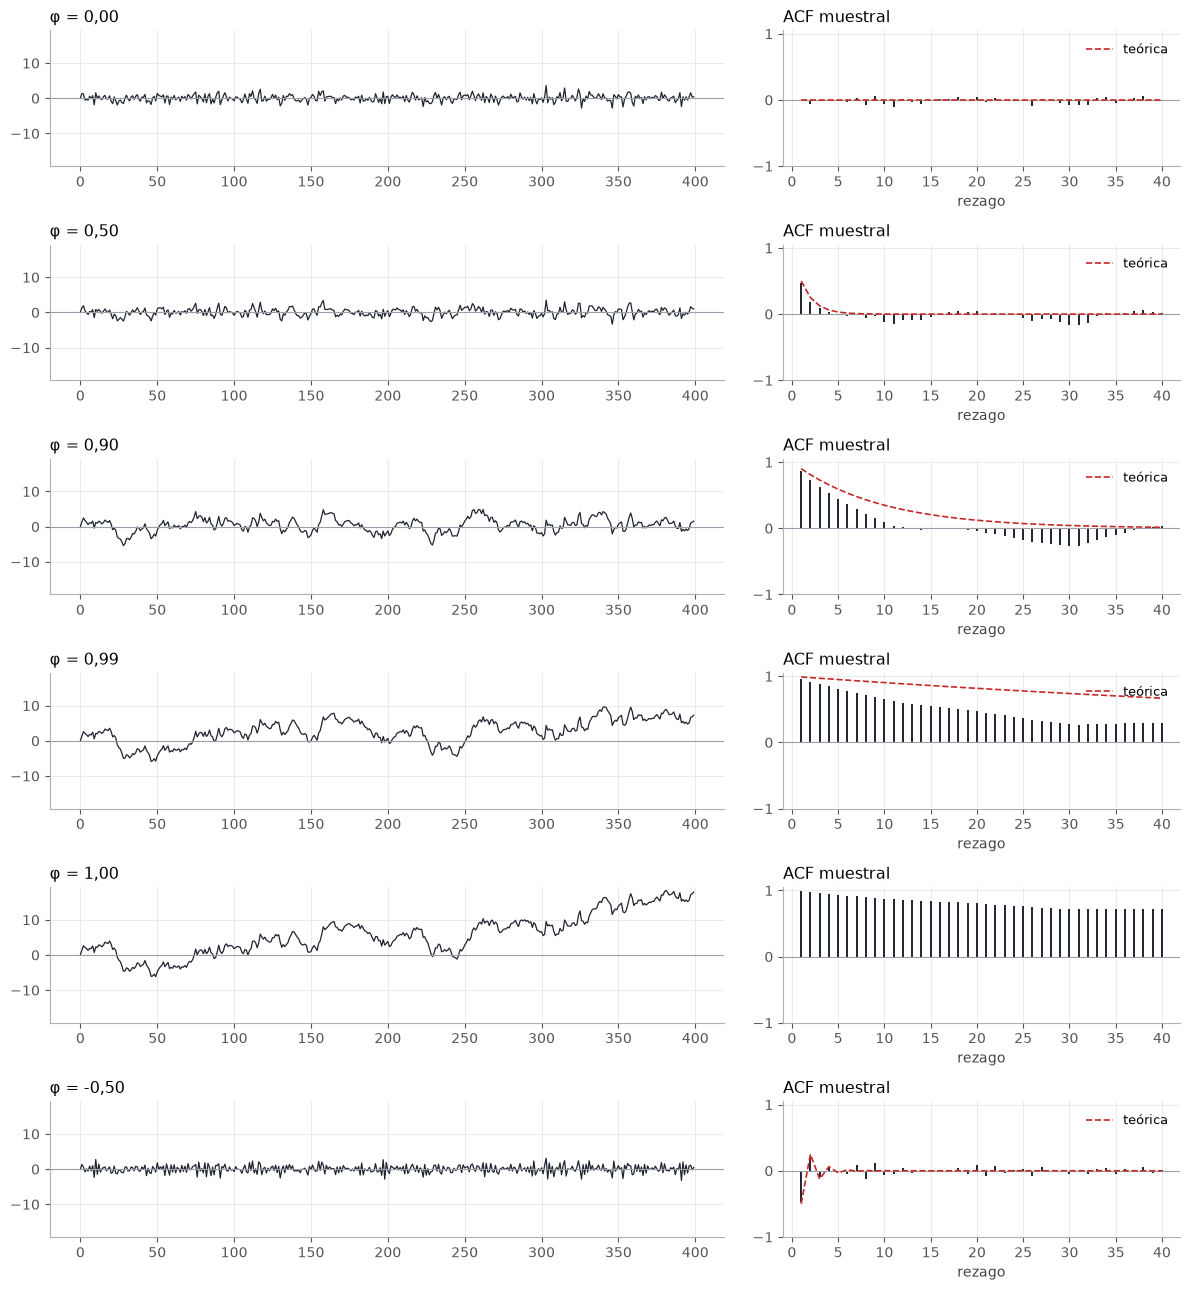

In [16]:
rng = np.random.default_rng(11)
eps = rng.normal(size=400)

def ar1(phi):
    x = np.empty(400)
    x[0] = eps[0]
    for t in range(1, 400):
        x[t] = phi * x[t - 1] + eps[t]
    return x

valores_phi = [0, 0.5, 0.9, 0.99, 1, -0.5]
simuladas = {phi: ar1(phi) for phi in valores_phi}
lim = max(np.abs(x).max() for x in simuladas.values()) * 1.05

fig, axes = plt.subplots(len(valores_phi), 2, figsize=(12, 13), gridspec_kw={"width_ratios": [1.7, 1]})
for fila, phi in enumerate(valores_phi):
    x = simuladas[phi]
    axes[fila, 0].plot(x, color=TINTA, lw=0.9)
    axes[fila, 0].axhline(0, color=GRIS, lw=0.8)
    axes[fila, 0].set_ylim(-lim, lim)
    axes[fila, 0].set_title(f"φ = {num(phi, 2)}")
    teorica = pd.Series([phi ** k for k in range(1, 41)], index=range(1, 41)) if abs(phi) < 1 else None
    barras_acf(axes[fila, 1], acf_simple(x, 40), "ACF muestral", teorica)
    axes[fila, 1].set_ylim(-1, 1.05)
    if 0 < phi < 1:
        print(f"φ = {num(phi, 2)}: un shock pierde la mitad de su efecto en {num(np.log(0.5) / np.log(phi), 1)} períodos")
fig.tight_layout()

Cuanto más cerca de 1 está $\phi$, más se aleja la serie del cero y más tarda en volver. Con $\phi = 0{,}99$ la serie es estacionaria, pero en 400 períodos se ve casi igual que una caminata. Con $\phi$ negativo, cada valor tiende a tener el signo contrario del anterior y la ACF alterna signos.

## Para seguir

1. Calcular la ACF y la PACF de `ecobici_diario.csv` entre 2022 y 2025. ¿Tiene picos en los múltiplos de 7? ¿Son más altos o más bajos que los del subte?
2. Aplicar `adfuller` al total diario de una sola línea (por ejemplo, la D en 2023 y 2024, con el cierre de enero a marzo de 2024) en niveles y con diferencias de 7 días. ¿Qué cambia?
3. Simular un AR(1) con $\phi = 0{,}95$ y estimar $\phi$ con una regresión de $x_t$ contra $x_{t-1}$ usando 50, 200 y 2.000 períodos. ¿Cuánto se aleja la estimación del valor verdadero?